In [28]:
pip install xlrd


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [29]:
import pandas as pd

df = pd.read_excel("GSAF5.xls")
df.shape

(7125, 23)

In [30]:
# Ver nulos por columna
df.isna().sum()

Date                 0
Year                 2
Type                18
Country             50
State              487
Location           567
Activity           583
Name               218
Sex                578
Age               2994
Injury              36
Fatal Y/N          561
Time              3527
Species           3131
Source              20
pdf                326
href formula       331
href               329
Case Number        327
Case Number.1      328
original order     326
Unnamed: 21       7124
Unnamed: 22       7123
dtype: int64

In [31]:
# Ver duplicados por filas
df.duplicated().sum()

np.int64(0)

In [32]:
# Eliminar filas y columnas vacías
df_clean = df.dropna(axis=1, how="all")   
df_clean = df_clean.dropna(axis=0, how="all")   
df_clean.columns = df_clean.columns.str.strip()
df_clean.shape

(7125, 23)

In [33]:
# Elimino duplicados
df_clean = df_clean.drop_duplicates()
df_clean.shape

(7125, 23)

In [34]:
# Elimino los nulos que me molestan de las columnas de mi hipotesis
df_clean = df_clean.dropna(subset=["Country"])
df_clean.shape

(7075, 23)

In [35]:
# Elimino los nulos de la columna Species y los reemplazo por Unknown, ya que son más de la mitad de las filas y no quiero perder información de otras columnas.
df_clean["Species"] = df_clean["Species"].fillna("Unknown")

In [36]:
# Elimino las columnas que no aportan (Unnamed, notas internas y las de códigos)
columnas_fuera = ["Unnamed: 21", "Unnamed: 22", "pdf", "href formula", "href",
                  "Case Number", "Case Number.1", "original order", "Source", "Name"]
df_clean = df_clean.drop(columns=columnas_fuera)
df_clean.shape

(7075, 13)

In [37]:
# Me quedo solo con  años fiables, desde antes de 1900 los hay mucho sin valor
df_clean["Year"] = pd.to_numeric(df_clean["Year"], errors="coerce")
df_clean = df_clean[df_clean["Year"] >= 1900]
df_clean.shape

(6349, 13)

In [38]:
# Limpio "Country"
print("Países distintos antes:", df_clean["Country"].nunique())

df_clean["Country"] = (df_clean["Country"]
                       .str.strip()
                       .str.upper()
                       .str.replace("?", "", regex=False)
                       .str.strip())

print("Países distintos después:", df_clean["Country"].nunique())
df_clean["Country"].value_counts().head(10)


Países distintos antes: 223
Países distintos después: 181


Country
USA                 2447
AUSTRALIA           1377
SOUTH AFRICA         569
BAHAMAS              137
PAPUA NEW GUINEA     132
BRAZIL               121
NEW ZEALAND          115
MEXICO                95
NEW CALEDONIA         66
ITALY                 62
Name: count, dtype: int64

In [39]:
# Limpio "Species"
import re
def limpiar_especie(texto):
    """Agrupa el texto libre de Species en una especie conocida."""
    texto = str(texto).lower()
    if texto == "unknown":
        return "Unknown"
    if re.search(r"not confirmed|unconfirmed|invalid|questionable", texto):
        return "Not confirmed"
    patrones = {
        "Sand tiger shark": r"sand tiger|raggedtooth|grey nurse",
        "White shark": r"white",
        "Tiger shark": r"tiger",
        "Bull shark": r"bull",
        "Blacktip shark": r"blacktip|black tip",
        "Nurse shark": r"nurse",
        "Bronze whaler": r"bronze|whaler",
        "Mako shark": r"mako",
        "Hammerhead": r"hammerhead",
    }
    for especie, patron in patrones.items():
        if re.search(patron, texto):
            return especie
    return "Unknown"

df_clean["Species_clean"] = df_clean["Species"].apply(limpiar_especie)
df_clean["Species_clean"].value_counts()

Species_clean
Unknown             4122
White shark          750
Not confirmed        421
Tiger shark          338
Bull shark           237
Blacktip shark       134
Sand tiger shark      88
Bronze whaler         86
Nurse shark           71
Mako shark            57
Hammerhead            45
Name: count, dtype: int64

In [40]:
# Termino de mirar "State"
df_clean["State"].value_counts().head(15)


State
Florida                  1168
New South Wales           459
Hawaii                    325
Queensland                323
California                322
Western Australia         234
KwaZulu-Natal             204
Western Cape Province     189
Eastern Cape Province     161
South Carolina            158
South Australia           111
North Carolina            110
Pernambuco                 80
Texas                      79
Victoria                   79
Name: count, dtype: int64

In [41]:
# Busco países escritos de distintas formas
print("Lista ordenada:")
print(sorted(df_clean["Country"].unique()))

print("\nVariantes de palabras sospechosas:")
print(df_clean[df_clean["Country"].str.contains("MARTIN|TRINIDAD|TOBAGO", na=False)]["Country"].value_counts())

print("\nPaíses que aparecen muy poco:")
print(df_clean["Country"].value_counts().tail(40))

Lista ordenada:
['ADMIRALTY ISLANDS', 'AMERICAN SAMOA', 'ANDAMAN / NICOBAR ISLANDAS', 'ANGOLA', 'ANTIGUA', 'ARGENTINA', 'ARUBA', 'ATLANTIC OCEAN', 'AUSTRALIA', 'AZORES', 'BAHAMAS', 'BANGLADESH', 'BARBADOS', 'BAY OF BENGAL', 'BELIZE', 'BERMUDA', 'BRAZIL', 'BRITISH ISLES', 'BRITISH OVERSEAS TERRITORY', 'BRITISH VIRGIN ISLANDS', 'BRITISH WEST INDIES', 'CANADA', 'CANARY ISLANDS', 'CAPE VERDE', 'CARIBBEAN SEA', 'CAYMAN ISLANDS', 'CENTRAL PACIFIC', 'CHILE', 'CHINA', 'COLOMBIA', 'COLUMBIA', 'COMOROS', 'CORAL SEA', 'COSTA RICA', 'CRETE', 'CROATIA', 'CUBA', 'CURACAO', 'CYPRUS', 'DIEGO GARCIA', 'DOMINICAN REPUBLIC', 'ECUADOR', 'EGYPT', 'EGYPT / ISRAEL', 'EL SALVADOR', 'ENGLAND', 'FALKLAND ISLANDS', 'FEDERATED STATES OF MICRONESIA', 'FIJI', 'FRANCE', 'FRENCH POLYNESIA', 'GABON', 'GALAPOGOS ISLANDS', 'GRAND CAYMAN', 'GREECE', 'GRENADA', 'GUAM', 'GUATEMALA', 'GULF OF ADEN', 'GUYANA', 'HAITI', 'HAWAII', 'HONDURAS', 'HONG KONG', 'ICELAND', 'INDIA', 'INDIAN OCEAN', 'INDONESIA', 'IRAN', 'IRAN / IRAQ', 

In [42]:
# Unifico países escritos de distintas formas
correcciones_pais = {
    "COLUMBIA": "COLOMBIA",
    "REUNION ISLAND": "REUNION",
    "ST. MARTIN": "ST MARTIN",
    "ST. MAARTIN": "ST MARTIN",
    "TURKS AND CAICOS": "TURKS & CAICOS",
    "UNITED ARAB EMIRATES (UAE)": "UNITED ARAB EMIRATES",
    "MALDIVE ISLANDS": "MALDIVES",
    "TRINIDAD": "TRINIDAD & TOBAGO",
    "TOBAGO": "TRINIDAD & TOBAGO",
    "ENGLAND": "UNITED KINGDOM",
    "SCOTLAND": "UNITED KINGDOM",
    "HAWAII": "USA",
    "GRAND CAYMAN": "CAYMAN ISLANDS",
    "WESTERN SAMOA": "SAMOA",
}
df_clean["Country"] = df_clean["Country"].replace(correcciones_pais)
print("Países distintos:", df_clean["Country"].nunique())

Países distintos: 167


In [43]:
# Época del año: saco el mes buscando su nombre con regex ("9-Mar-2018" -> Mar)
mes_texto = df_clean["Date"].astype(str).str.extract(
    r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)", flags=re.IGNORECASE)[0]
df_clean["Month"] = pd.to_datetime(mes_texto.str.capitalize(), format="%b", errors="coerce").dt.month

In [44]:
# Las fechas recientes vienen como "2025-06-11": saco el número del mes del medio
mes_iso = df_clean["Date"].astype(str).str.extract(r"^\d{4}-(\d{2})-\d{2}")[0]
df_clean["Month"] = df_clean["Month"].fillna(pd.to_numeric(mes_iso, errors="coerce"))

print("Ataques con mes conocido:", df_clean["Month"].notna().sum(), "de", len(df_clean))
df_clean["Month"].value_counts().sort_index()

Ataques con mes conocido: 6057 de 6349


Month
1.0     535
2.0     399
3.0     432
4.0     464
5.0     429
6.0     517
7.0     740
8.0     619
9.0     570
10.0    473
11.0    424
12.0    455
Name: count, dtype: int64

In [45]:
# Países del hemisferio sur (los principales con ataques)
paises_sur = ["AUSTRALIA", "SOUTH AFRICA", "NEW ZEALAND", "BRAZIL", "PAPUA NEW GUINEA",
              "NEW CALEDONIA", "FIJI", "MOZAMBIQUE", "REUNION", "ARGENTINA", "CHILE",
              "URUGUAY", "FRENCH POLYNESIA", "VANUATU", "TONGA", "SAMOA", "MADAGASCAR",
              "MAURITIUS", "NAMIBIA", "ANGOLA", "PERU", "SOLOMON ISLANDS", "INDONESIA"]

df_clean["Hemisphere"] = df_clean["Country"].apply(lambda pais: "Sur" if pais in paises_sur else "Norte")
df_clean["Hemisphere"].value_counts()

Hemisphere
Norte    3649
Sur      2700
Name: count, dtype: int64

In [46]:
# Estaciones en cada hemisferio (en el sur van al revés)
estaciones_norte = {12: "Invierno", 1: "Invierno", 2: "Invierno",
                    3: "Primavera", 4: "Primavera", 5: "Primavera",
                    6: "Verano", 7: "Verano", 8: "Verano",
                    9: "Otoño", 10: "Otoño", 11: "Otoño"}
estaciones_sur = {12: "Verano", 1: "Verano", 2: "Verano",
                  3: "Otoño", 4: "Otoño", 5: "Otoño",
                  6: "Invierno", 7: "Invierno", 8: "Invierno",
                  9: "Primavera", 10: "Primavera", 11: "Primavera"}

# Primero aplico las del norte a todos, y luego corrijo las filas del sur
df_clean["Season"] = df_clean["Month"].map(estaciones_norte)
es_sur = df_clean["Hemisphere"] == "Sur"
df_clean.loc[es_sur, "Season"] = df_clean.loc[es_sur, "Month"].map(estaciones_sur)

df_clean["Season"].value_counts(dropna=False)

Season
Verano       2479
Otoño        1563
Primavera    1229
Invierno      786
NaN           292
Name: count, dtype: int64

ANÁLISIS EDA

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

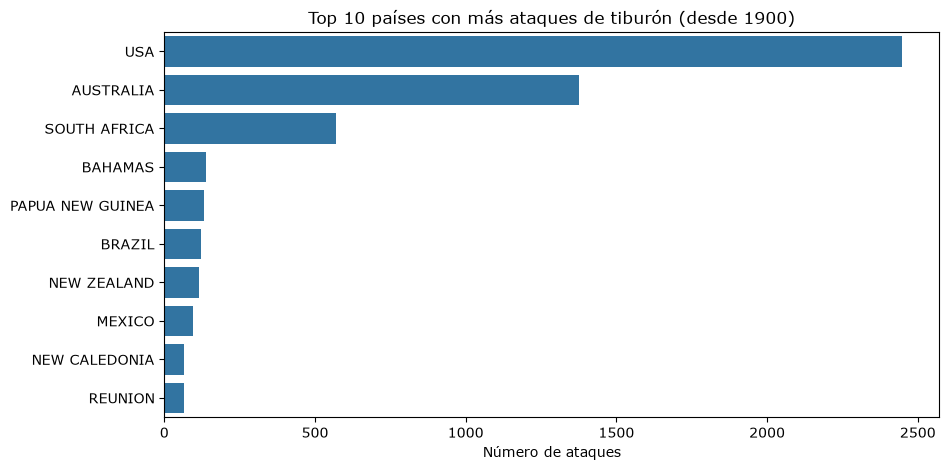

In [48]:
# Top 10 países con más ataques
top_paises = df_clean["Country"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_paises.values, y=top_paises.index)
plt.title("Top 10 países con más ataques de tiburón (desde 1900)")
plt.xlabel("Número de ataques")
plt.ylabel("")
plt.show()

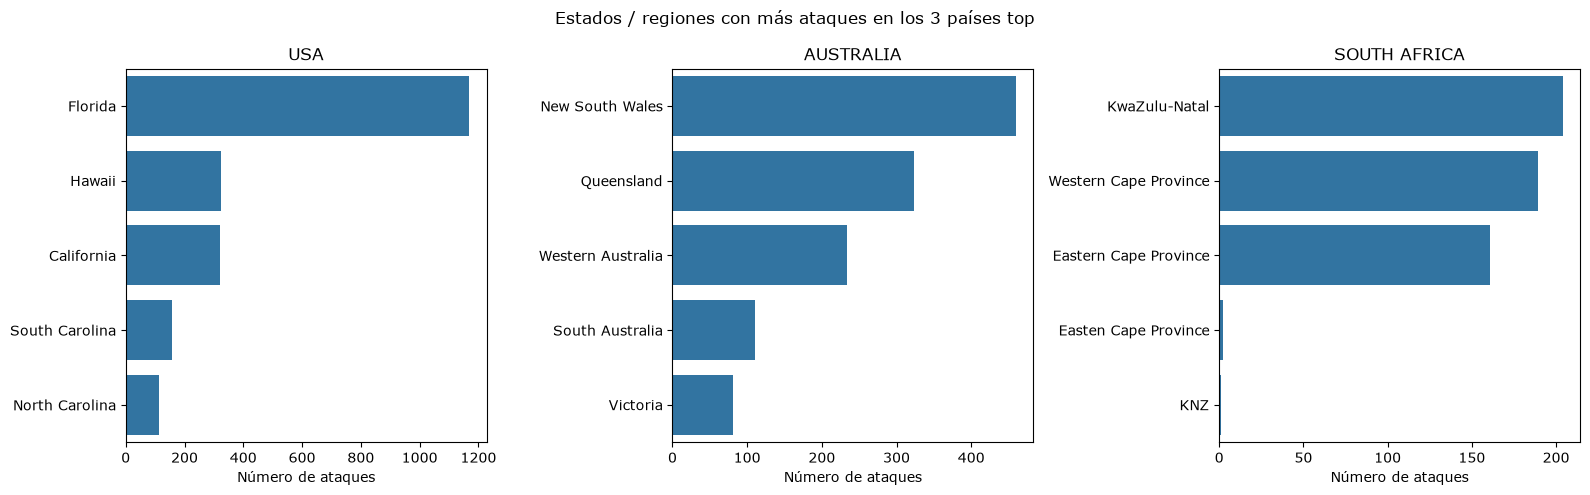

In [49]:
# Quito espacios sobrantes en State para que "Florida " y "Florida" cuenten igual
df_clean["State"] = df_clean["State"].str.strip()

# Selecciono los 3 paises con más ataques
top3_paises = df_clean["Country"].value_counts().head(3).index.tolist()
top3_paises

# Ahora el gráfico por país con los 5 estados donde más ataques hay
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, pais in enumerate(top3_paises):
    datos_pais = df_clean[df_clean["Country"] == pais]
    top_states = datos_pais["State"].value_counts().head(5)

    sns.barplot(x=top_states.values, y=top_states.index, ax=axes[i])
    axes[i].set_title(pais)
    axes[i].set_xlabel("Número de ataques")
    axes[i].set_ylabel("")

plt.suptitle("Estados / regiones con más ataques en los 3 países top")
plt.tight_layout()
plt.show()

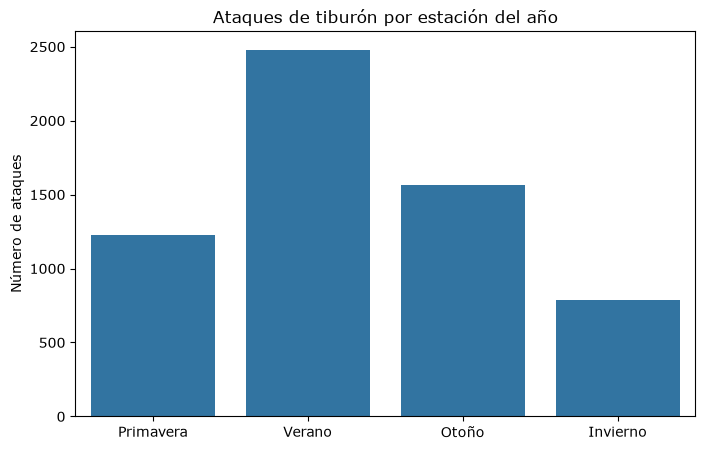

In [50]:
# Ataques por estación (ya ajustada por hemisferio)
orden = ["Primavera", "Verano", "Otoño", "Invierno"]
ataques_estacion = df_clean["Season"].value_counts().reindex(orden)

plt.figure(figsize=(8, 5))
sns.barplot(x=ataques_estacion.index, y=ataques_estacion.values)
plt.title("Ataques de tiburón por estación del año")
plt.ylabel("Número de ataques")
plt.xlabel("")
plt.show()

In [ ]:
# Tabla dinámica: ataques por país (top 5) y estación
top5 = df_clean["Country"].value_counts().head(5).index

tabla = pd.pivot_table(
    df_clean[df_clean["Country"].isin(top5)],
    index="Country",       
    columns="Season",      
    values="Date",         
    aggfunc="count"        
)
tabla = tabla[["Primavera", "Verano", "Otoño", "Invierno"]]   
tabla

Season,Primavera,Verano,Otoño,Invierno
Country,,,,
AUSTRALIA,304,549,309,191
BAHAMAS,19,77,21,17
PAPUA NEW GUINEA,29,23,24,24
SOUTH AFRICA,90,224,138,91
USA,477,1031,675,207


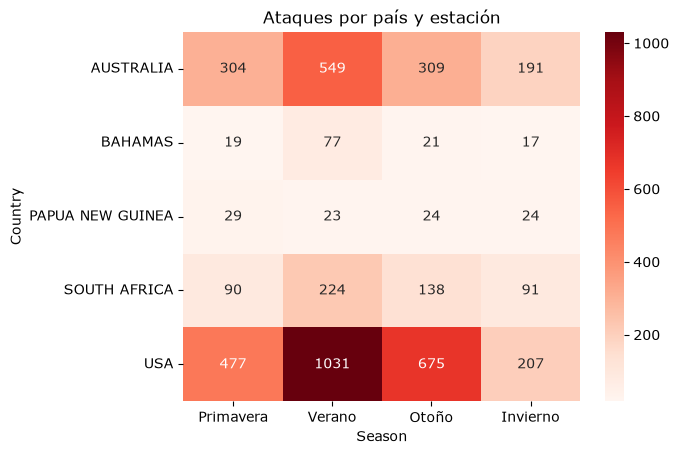

In [55]:
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Reds")
plt.title("Ataques por país y estación")
plt.show()

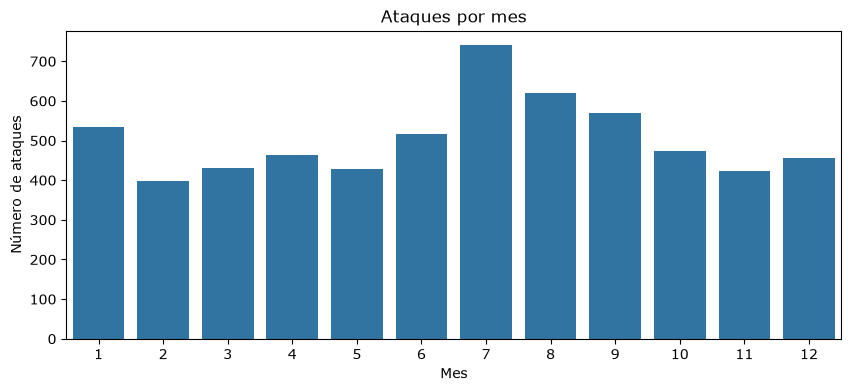

In [51]:
# Ataque por mes del año
plt.figure(figsize=(10, 4))
sns.barplot(x=df_clean["Month"].value_counts().sort_index().index.astype(int),
            y=df_clean["Month"].value_counts().sort_index().values)
plt.title("Ataques por mes")
plt.xlabel("Mes")
plt.ylabel("Número de ataques")
plt.show()

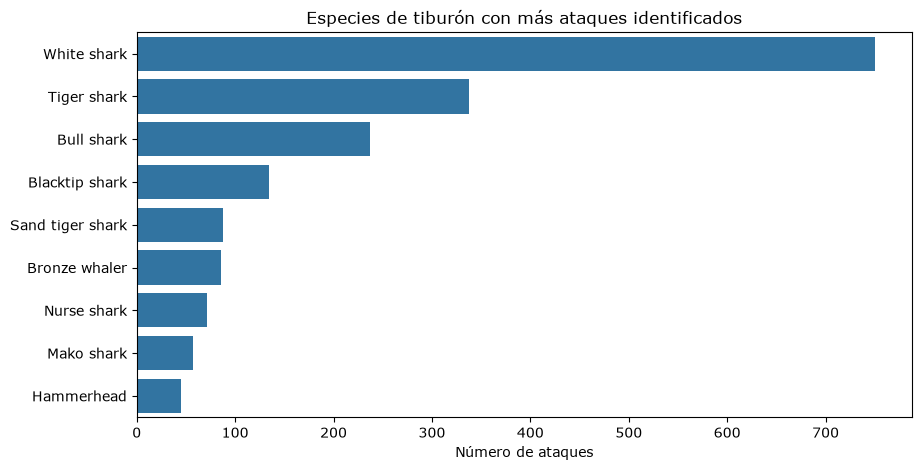

In [52]:
# Especies que más atacan. Quito "Unknown" y "Not confirmed" porque no dicen qué especie fue
especies = df_clean[~df_clean["Species_clean"].isin(["Unknown", "Not confirmed"])]
top_especies = especies["Species_clean"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=top_especies.values, y=top_especies.index)
plt.title("Especies de tiburón con más ataques identificados")
plt.xlabel("Número de ataques")
plt.ylabel("")
plt.show()

In [53]:
# Porcentaje de ataques con especie identificada
identificados = len(especies)
total = len(df_clean)
print(f"Especie identificada en {identificados} de {total} ataques ({identificados / total * 100:.1f}%)")

Especie identificada en 1806 de 6349 ataques (28.4%)


## Conclusiones

Después de limpiar el dataset me quedé con unos 6.300 ataques desde 1900, y lo primero que salta a la vista es que casi todo pasa en tres países: USA, Australia y Sudáfrica. Pero al bajar a nivel de estado vi que el riesgo no se reparte igual. Florida sola tiene más ataques que muchos países enteros, así que para YAJA tendría más sentido ajustar el precio por región que por país.

Con la época del año me llevé una sorpresa. Al principio iba a mirar solo los meses, hasta que caímos en que julio es verano en Florida pero invierno en Australia. Ajustándolo por hemisferio, en verano hay casi el triple de ataques que en invierno.

Lo del tipo de tiburón me deja más dudas. El blanco, el tigre y el toro son los que más salen, pero en 7 de cada 10 ataques nadie sabe qué tiburón fue, así que no me fiaría mucho de esa conclusión.
Limpiar los datos cambia los resultados: un error con las fechas me metió más de 200 ataques falsos en enero. Y hay un límite que no puedo arreglar: el dataset cuenta ataques, no cuánta gente se mete al agua, así que puedo decir dónde hay más ataques, pero no dónde es más peligroso bañarse.

Si yo tuviera que ponerle precio al seguro con estos datos, empezaría por el destino. No tiene sentido cobrar lo mismo a alguien que va a surfear a Florida que a alguien que se va de vacaciones a Nueva York. Pondría un recargo en las zonas que más se repiten en el análisis (Florida, New South Wales, Queensland y KwaZulu-Natal) y dejaría el precio base para el resto.

Lo segundo sería la fecha del viaje. Un viaje en verano tiene bastante más riesgo que uno en invierno, pero ojo: el verano depende de a dónde vayas. Un cliente que viaja a Australia en julio está en pleno invierno allí, y la póliza debería tenerlo en cuenta.

El tipo de tiburón, en cambio, no lo usaría para fijar precios. Hay demasiados casos sin identificar, y además el cliente no puede elegir qué tiburón se va a encontrar. Como mucho serviría para dar consejos de seguridad según la zona.

Antes de llevar esto a producción le pediría a la empresa datos de cuánta gente se baña o hace surf en cada sitio. Con eso podríamos calcular un riesgo real por persona y no solo contar ataques, que es la gran limitación de este análisis.